In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [6]:
df = pd.read_csv('IPL_Matches_tail_300.csv')
df.head()

,date,season,city,venue,team1,team2,toss_winner,toss_decision,team1_runs,team1_wickets,...,win_by_wickets,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players
0,20-05-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Chennai Super Kings,Rajasthan Royals,Chennai Super Kings,bat,150.0,6,...,5,R Ashwin,M Nayyar,CB Gaffaney,NA Patwardhan,YC Barde,PG Pathak,20,"RD Gaikwad, DP Conway, MM Ali, N Jagadeesan, A...","YBK Jaiswal, JC Buttler, SV Samson, D Padikkal..."
1,21-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Delhi Capitals,Mumbai Indians,Mumbai Indians,field,159.0,7,...,5,JJ Bumrah,J Srinath,Nitin Menon,Tapan Sharma,HAS Khalid,GR Sadashiv Iyer,20,"PP Shaw, DA Warner, MR Marsh, RR Pant, SN Khan...","Ishan Kishan, RG Sharma, D Brevis, Tilak Varma..."
2,22-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,Punjab Kings,Sunrisers Hyderabad,bat,157.0,8,...,5,Harpreet Brar,J Srinath,AK Chaudhary,NA Patwardhan,CB Gaffaney,Navdeep Singh,20,"PK Garg, Abhishek Sharma, RA Tripathi, AK Mark...","JM Bairstow, S Dhawan, M Shahrukh Khan, MA Aga..."
3,24-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Rajasthan Royals,Gujarat Titans,Gujarat Titans,field,188.0,6,...,7,DA Miller,M Nayyar,BNJ Oxenford,VK Sharma,MA Gough,J Madanagopal,20,"YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...","WP Saha, Shubman Gill, MS Wade, HH Pandya, DA ..."
4,25-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Royal Challengers Bangalore,Lucknow Super Giants,Lucknow Super Giants,field,207.0,4,...,0,RM Patidar,M Nayyar,J Madanagopal,MA Gough,BNJ Oxenford,VK Sharma,20,"V Kohli, F du Plessis, RM Patidar, GJ Maxwell,...","Q de Kock, KL Rahul, M Vohra, DJ Hooda, MP Sto..."


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 25 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             300 non-null    object 
 1   season           300 non-null    int64  
 2   city             300 non-null    object 
 3   venue            300 non-null    object 
 4   team1            300 non-null    object 
 5   team2            300 non-null    object 
 6   toss_winner      300 non-null    object 
 7   toss_decision    300 non-null    object 
 8   team1_runs       293 non-null    float64
 9   team1_wickets    300 non-null    int64  
 10  team2_runs       293 non-null    float64
 11  team2_wickets    300 non-null    int64  
 12  winner           288 non-null    object 
 13  result_type      300 non-null    object 
 14  win_by_runs      300 non-null    int64  
 15  win_by_wickets   300 non-null    int64  
 16  player_of_match  290 non-null    object 
 17  match_referee   

In [23]:
column = "team1_runs"
df[[column]].describe()

,team1_runs
count,293.000000
mean,188.136519
std,37.459500
min,25.000000
25%,163.000000
50%,191.000000
75%,212.000000
max,287.000000


# Z scores

In [24]:
scaler = StandardScaler()
df['Z_score'] = scaler.fit_transform(df[[column]])

df[[column , "Z_score"]].head(10)

,team1_runs,Z_score
0,150.0,-1.019815
1,159.0,-0.779145
2,157.0,-0.832627
3,188.0,-0.003651
4,207.0,0.504432
5,157.0,-0.832627
6,130.0,-1.554639
7,178.0,-0.271062
8,193.0,0.130055
9,191.0,0.076573


In [42]:
outliers = df[abs(df["Z_score"]) >= 3]
print("Number of outliers : " , len(outliers))
outliers[[column , "Z_score"]].head()

Number of outliers :  2


,team1_runs,Z_score
237,25.0,-4.362461
264,75.0,-3.025403


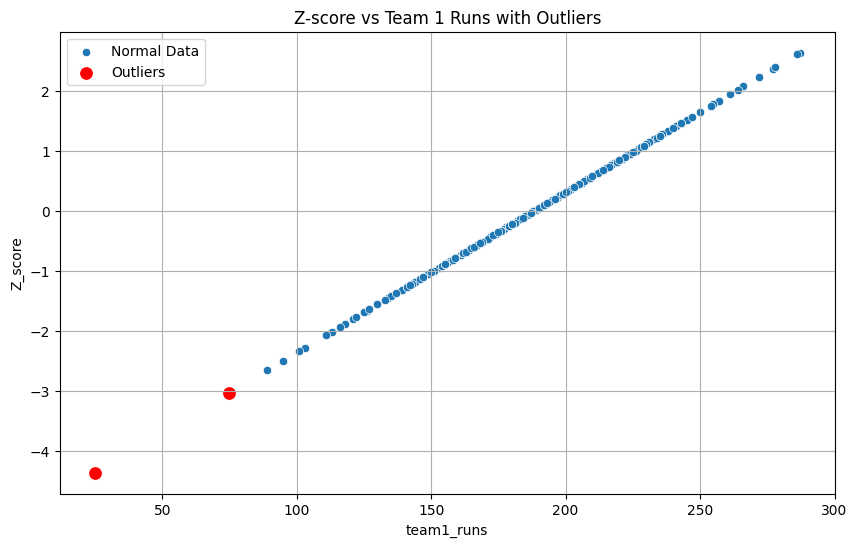

In [33]:
plt.figure(figsize = (10,6))
sns.scatterplot(x='team1_runs', y='Z_score', data=df, label='Normal Data')
sns.scatterplot(x='team1_runs', y='Z_score', data=outliers, color='red', s=100, label='Outliers')
plt.xlabel("team1_runs")
plt.ylabel("Z_score")
plt.title("Z-score vs Team 1 Runs with Outliers")
plt.legend()
plt.grid(True)
plt.show()

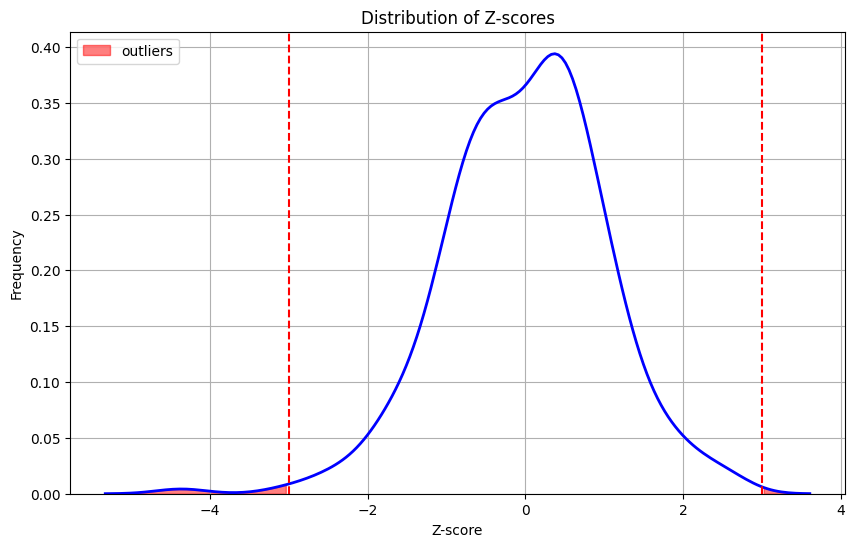

In [ ]:
plt.figure(figsize=(10, 6))

ax = sns.kdeplot(data = df , x = "Z_score" ,  color = "blue" , linewidth = 2 )
x,y = ax.lines[0].get_data()
plt.fill_between(x,y, where = ( x > 3) , color = "red" , alpha = 0.5 , label = 'outliers')
plt.fill_between(x,y, where = ( x < -3) , color = "red" , alpha = 0.5)

plt.axvline(3, color = 'red' , linestyle = '--')
plt.axvline(-3 , color = 'red' , linestyle = '--')

plt.title('Distribution of Z-scores')
plt.xlabel('Z-score')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()

# IQR Method

In [ ]:
from matplotlib.lines import lineStyles

q1 = df['team2_runs'].quantile(0.25)
q3 = df['team2_runs'].quantile(0.75)
median = df['team2_runs'].quantile(0.5)

IQR = q3 - q1
lower = q1 - 1.5 * IQR
upper = q3 + 1.5 * IQR

print(f"lower : {lower} ")
print(f"upper : {upper}")



lower : 80.0 
upper : 272.0


In [78]:
outliers = df[(df['team2_runs'] < lower) | (df['team2_runs'] > upper)]
outliers['team2_runs'].head()

,team2_runs
52,0.0
66,59.0
195,7.0
206,0.0
209,0.0


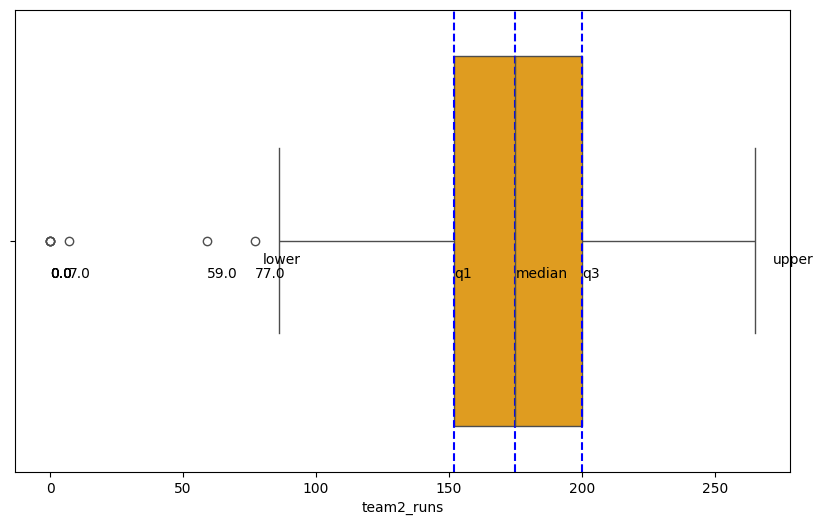

In [79]:
plt.figure(figsize = (10,6))
sns.boxplot(data = df , x = "team2_runs" , color = 'orange')

for x in outliers['team2_runs'] :
  plt.text(x , 0.08 , str(x) , color = 'black')

plt.axvline(q1 , color = 'blue' , linestyle  = '--')
plt.text(q1, 0.08 , "q1")

plt.axvline(median , color = 'blue' , linestyle  = '--')
plt.text(median, 0.08 , "median")

plt.axvline(q3 , color = 'blue' , linestyle  = '--')
plt.text(q3, 0.08 , "q3")

plt.text(lower, 0.05 , "lower")
plt.text(upper, 0.05 , "upper")

plt.show()

# Trimming the dataset

In [82]:
df.shape

(300, 26)

In [83]:
trim_df = df[(df['team2_runs'] <=  upper) & (df['team2_runs'] >= lower) ]
trim_df.shape

(286, 26)

<Axes: xlabel='team2_runs'>

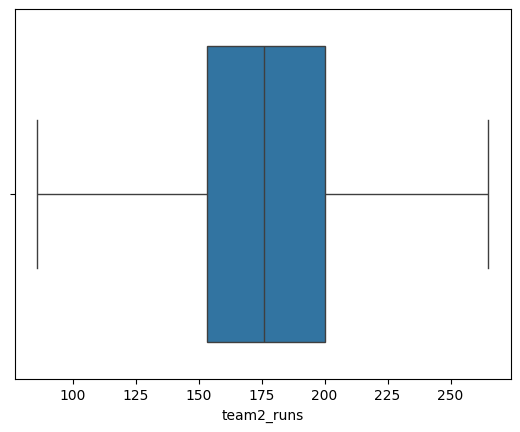

In [84]:
# after trimming

sns.boxplot(data = trim_df , x = 'team2_runs')

# capping the dataset

In [86]:
cap_df = df.copy()
cap_df['team2_runs'] = cap_df['team2_runs'].clip(lower , upper)
cap_df.shape

(300, 26)

<Axes: xlabel='team2_runs'>

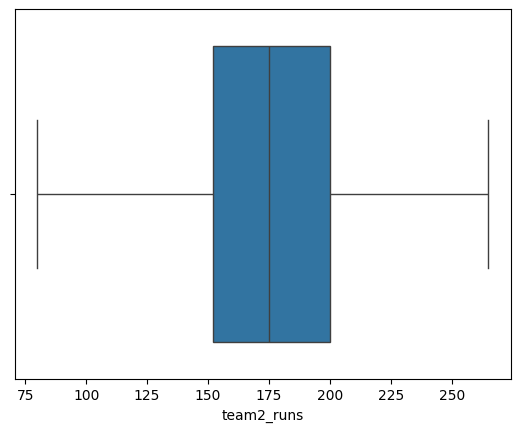

In [87]:
sns.boxplot(data = cap_df , x = 'team2_runs')